# 01 · The leakage trap, found before we walk into it

We are about to scrape zodiac playlists and train a classifier on them. This notebook
runs that plan first, on data whose structure we control, to find out what it will
report and whether that number will mean anything.

The answer is that it will report something impressive and the number will be close to
worthless. This is worth knowing **now**, while the collection pipeline is still being
written, because the fix is a property of how the data is split and deduplicated — and
that has to be designed in, not bolted on afterwards.

> **A note on what this notebook is not.** The project's original deck carries accuracy
> figures for this classifier. Those figures were placeholders describing an intended
> system, not measurements — the 2023 attempt was abandoned before it produced results,
> and its data and code are gone. So nothing here is a correction of a past experiment.
> It is a dry run of a planned one.

What makes the trap dangerous is that it does not look like a bug. There is no error, no
warning, no suspicious-looking code. The pipeline runs cleanly and prints a number many
times better than chance, and every instinct says to believe it.

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from lovify_ml import schema as S, data, synthetic as syn, zodiac as Z, viz

pd.set_option("display.width", 170, "display.max_columns", 40)

catalog = data.load_catalog(n_synthetic=8000)
zodiac = data.load_zodiac(catalog)

print(f"\n{len(zodiac):,} rows  ·  {zodiac[S.TRACK_ID].nunique():,} unique tracks  ·  "
      f"{zodiac[S.STAR_SIGN].nunique()} classes")
print(f"chance accuracy = 1/12 = {S.CHANCE_ACCURACY:.4f}")

[data] SYNTHETIC catalog (8,000 tracks). Drop a Kaggle dump at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/tracks.csv to use real songs.


[data] SYNTHETIC zodiac playlists. Drop your scrape at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/zodiac.csv to use real ones.

6,000 rows  ·  2,042 unique tracks  ·  12 classes
chance accuracy = 1/12 = 0.0833


## 1 · The plan, executed literally

The design is the obvious one, and it is what the project set out to do: search Spotify
for each sign, take the playlists that come back, label every track with the sign of the
playlist it came from, and train a classifier on the audio features.

Two ways to split that data for evaluation. First, holding out a fixed slice per sign —
the straightforward reading of "use some of each class for validation":

In [2]:
train, test = Z.contiguous_split(zodiac, n_per_sign=30)
res_contig = Z.benchmark(train, test)
res_contig

,model,accuracy,vs_chance
0,Random forest,0.772222,9.266667
1,Decision tree,0.741667,8.900000
2,SVM (rbf),0.286111,3.433333
3,KNN (k=15),0.283333,3.400000
4,Decision tree (depth 8),0.250000,3.000000
5,Logistic regression,0.152778,1.833333
6,Dummy (stratified),0.097222,1.166667
7,Dummy (most frequent),0.083333,1.000000


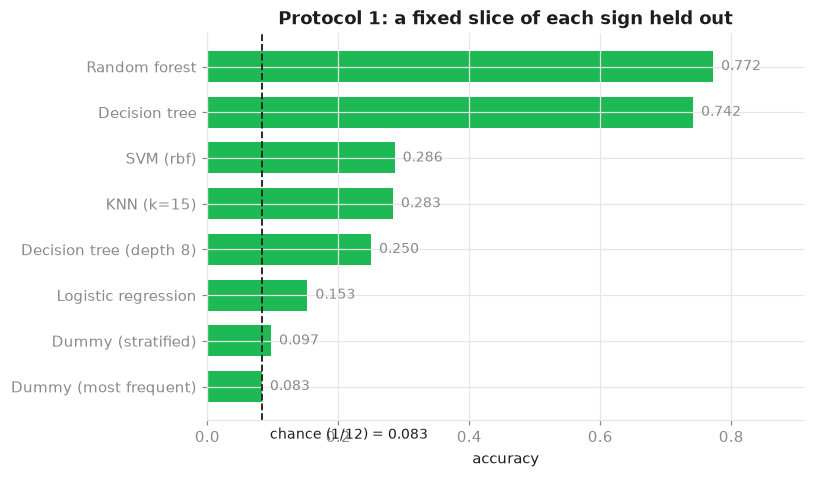

In [3]:
viz.bar_results(res_contig, "accuracy", "model",
                "Protocol 1: a fixed slice of each sign held out",
                reference=S.CHANCE_ACCURACY, reference_label="chance (1/12)")
plt.show()

Roughly 77% on a twelve-class problem, against a chance rate of 8.3%. That is a
nine-fold improvement, and it is the kind of number that ends an investigation rather
than starting one.

Second way, a plain random 75/25 split of the rows, which is what most people mean by
"train/test split":

In [4]:
train, test = Z.naive_split(zodiac, test_size=0.25, seed=0)
res_naive = Z.benchmark(train, test)
res_naive

,model,accuracy,vs_chance
0,Random forest,0.700000,8.400
1,Decision tree,0.690000,8.280
2,SVM (rbf),0.240000,2.880
3,KNN (k=15),0.234667,2.816
4,Decision tree (depth 8),0.230000,2.760
5,Logistic regression,0.152667,1.832
6,Dummy (stratified),0.074000,0.888
7,Dummy (most frequent),0.068000,0.816


Still far above chance, and the two protocols roughly agree with each other —
which is exactly the kind of corroboration that makes a result feel safe. Two different
splits, same story.

Notice also that the two tree models sit at the top and the linear model near the bottom.
Hold that thought; it is a clue, and section 3 explains it.

## 2 · What those splits are actually measuring

Before trusting either number, ask a question that has nothing to do with models: **how
many of the test rows are tracks the classifier has already seen during training?**

A playlist scrape repeats itself heavily. Ten different "Aries" playlists overlap, so the
same track appears many times over, and splitting by *row* scatters those copies across
both sides of the split.

In [5]:
def leak_report(train, test, name):
    seen = set(train[S.TRACK_ID])
    in_train = test[S.TRACK_ID].isin(seen)
    pairs = set(zip(train[S.TRACK_ID], train[S.STAR_SIGN]))
    same_label = [(t, s) in pairs for t, s in zip(test[S.TRACK_ID], test[S.STAR_SIGN])]
    return {
        "protocol": name,
        "test rows": len(test),
        "track seen in train": f"{in_train.mean():.1%}",
        "same (track, label) in train": f"{np.mean(same_label):.1%}",
    }

rows = []
tr, te = Z.contiguous_split(zodiac, 30);             rows.append(leak_report(tr, te, "fixed slice per sign"))
tr, te = Z.naive_split(zodiac, 0.25);                rows.append(leak_report(tr, te, "random row split"))
tr, te = Z.honest_split(Z.deduplicate(zodiac), .25); rows.append(leak_report(tr, te, "dedup + grouped"))
pd.DataFrame(rows)

,protocol,test rows,track seen in train,"same (track, label) in train"
0,fixed slice per sign,360,90.3%,89.4%
1,random row split,1500,83.8%,80.9%
2,dedup + grouped,511,0.0%,0.0%


The last column is the whole story. Under both of the first two protocols, the
overwhelming majority of test rows are tracks the model has already been trained on —
and trained on with **the same label it is now being asked to predict**.

The model is not inferring a zodiac sign from audio features. It is recognising a song
it has already been given the answer for. The features act as a fingerprint, and the
classifier is a lookup table with a tree-shaped index.

### The experiment that settles it

If the accuracy is recognition rather than inference, it should hold up on test rows
whose track appeared in training and collapse on rows whose track did not. Same model,
same test set, scored separately on each half.

In [6]:
train, test = Z.naive_split(zodiac, test_size=0.25, seed=0)
seen = set(train[S.TRACK_ID])
mask_seen = test[S.TRACK_ID].isin(seen).to_numpy()

from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=0).fit(
    train[S.AUDIO_FEATURES].to_numpy(float), train[S.STAR_SIGN].to_numpy())

acc_seen = tree.score(test[mask_seen][S.AUDIO_FEATURES].to_numpy(float),
                      test[mask_seen][S.STAR_SIGN].to_numpy())
acc_unseen = tree.score(test[~mask_seen][S.AUDIO_FEATURES].to_numpy(float),
                        test[~mask_seen][S.STAR_SIGN].to_numpy())

print("one decision tree, one test set, split by whether the track leaked:")
print(f"  track WAS in training    (n={mask_seen.sum():>5,}) : {acc_seen:.1%}")
print(f"  track was NOT in training (n={(~mask_seen).sum():>5,}) : {acc_unseen:.1%}")
print(f"  chance                                  : {S.CHANCE_ACCURACY:.1%}")

one decision tree, one test set, split by whether the track leaked:
  track WAS in training    (n=1,257) : 81.0%
  track was NOT in training (n=  243) : 7.0%
  chance                                  : 8.3%


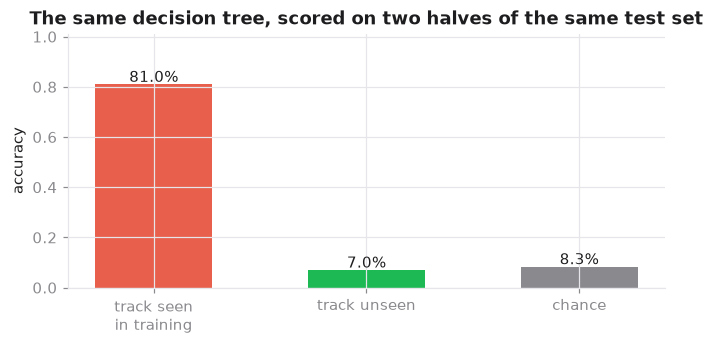

In [7]:
fig, ax = plt.subplots(figsize=(7, 3))
bars = ["track seen\nin training", "track unseen", "chance"]
vals = [acc_seen, acc_unseen, S.CHANCE_ACCURACY]
ax.bar(bars, vals, color=[viz.WARN, viz.ACCENT, viz.MUTED], width=.55)
for i, v in enumerate(vals):
    ax.text(i, v + .01, f"{v:.1%}", ha="center", fontsize=10)
ax.set_title("The same decision tree, scored on two halves of the same test set")
ax.set_ylabel("accuracy"); ax.set_ylim(0, max(vals) * 1.25)
plt.show()

On songs it has seen, the model is excellent. On songs it has not seen — the
only ones that matter, since a shipped classifier meets new songs constantly — it is at
chance.

The headline accuracy is a weighted average of those two numbers, and the weight is set
by how duplicate-heavy the scrape happens to be. It is a measurement of the data
collection, not of the model.

## 3 · Why the tree beat the linear model

Section 1 flagged that the decision tree and random forest topped the table while
logistic regression trailed. That ordering is itself a symptom.

An unpruned decision tree can carve feature space into arbitrarily fine regions, down to
one training point each. That is exactly the capability needed to memorise a fingerprint.
Logistic regression cannot do it — a single linear boundary per class has nowhere to
store a lookup table — so it is *unable* to exploit the leak and reports a lower,
more honest number.

**Under leakage, model ranking inverts: the more a model can memorise, the better it
scores.** So when a flexible model beats a rigid one by a wide margin on a task that
should be near-impossible, that gap is evidence about the data, not about the models.

In [8]:
comparison = res_naive.set_index("model")["accuracy"]
flexible = ["Decision tree", "Random forest"]
rigid = ["Logistic regression", "Dummy (stratified)"]
print("under the leaky split:")
for m in flexible + rigid:
    if m in comparison.index:
        kind = "memorises easily" if m in flexible else "cannot memorise"
        print(f"  {m:<24} {comparison[m]:.3f}   ({kind})")

under the leaky split:
  Decision tree            0.690   (memorises easily)
  Random forest            0.700   (memorises easily)
  Logistic regression      0.153   (cannot memorise)
  Dummy (stratified)       0.074   (cannot memorise)


## 4 · The protocol that measures the right thing

Two changes, and both are required:

1. **Deduplicate** to one row per track. Where curators disagreed, take the majority
   label (`strategy="majority"`) or drop the track entirely (`strategy="unanimous"`).
2. **Split by group**, so a track is wholly in train or wholly in test and can never
   straddle the boundary.

In [9]:
for strategy in ["majority", "unanimous"]:
    clean = Z.deduplicate(zodiac, strategy)
    tr, te = Z.honest_split(clean, test_size=0.25, seed=0)
    res = Z.benchmark(tr, te)
    print(f"\n=== dedup='{strategy}'  ({len(clean):,} tracks kept of "
          f"{zodiac[S.TRACK_ID].nunique():,}) ===")
    print(res.to_string(index=False))


=== dedup='majority'  (2,042 tracks kept of 2,042) ===
                  model  accuracy  vs_chance
    Logistic regression  0.148728   1.784736
              SVM (rbf)  0.140900   1.690802
          Random forest  0.125245   1.502935
Decision tree (depth 8)  0.117417   1.409002
     Dummy (stratified)  0.097847   1.174168
          Decision tree  0.095890   1.150685
             KNN (k=15)  0.095890   1.150685
  Dummy (most frequent)  0.080235   0.962818



=== dedup='unanimous'  (1,745 tracks kept of 2,042) ===
                  model  accuracy  vs_chance
    Logistic regression  0.153318   1.839817
          Random forest  0.137300   1.647597
              SVM (rbf)  0.128146   1.537757
             KNN (k=15)  0.114416   1.372998
          Decision tree  0.112128   1.345538
     Dummy (stratified)  0.082380   0.988558
Decision tree (depth 8)  0.082380   0.988558
  Dummy (most frequent)  0.077803   0.933638


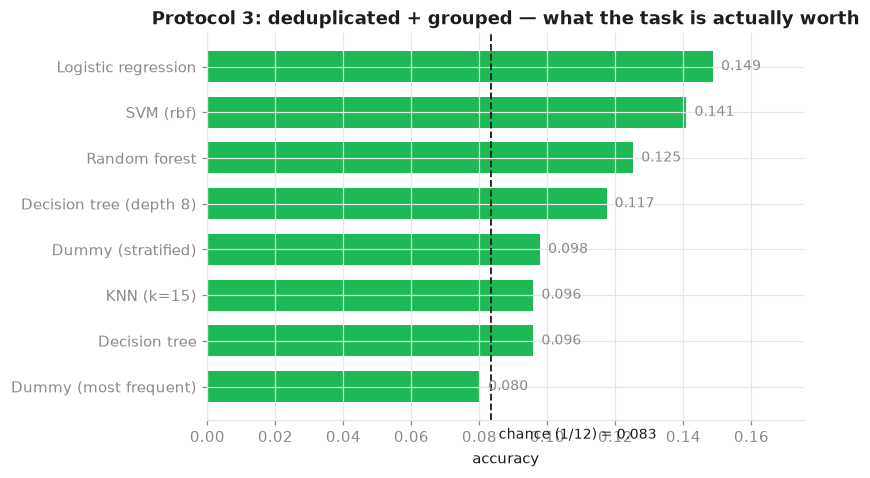

In [10]:
clean = Z.deduplicate(zodiac, "majority")
tr, te = Z.honest_split(clean, test_size=0.25, seed=0)
res_honest = Z.benchmark(tr, te)

viz.bar_results(res_honest, "accuracy", "model",
                "Protocol 3: deduplicated + grouped — what the task is actually worth",
                reference=S.CHANCE_ACCURACY, reference_label="chance (1/12)")
plt.show()

From the 70-77% the leaky protocols reported down to about 15%. Nothing about
the model changed; the only difference is that the test set no longer contains the
answers.

Note that the tree-versus-linear ordering has also flipped. With nothing left to
memorise, the flexible models lose their advantage.

### Cross-validated, so it is not one lucky split

`GroupKFold` keeps every track entirely inside a single fold.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "Random forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=0),
}
for name, m in models.items():
    s = Z.grouped_cv_score(clean, m, n_splits=5)
    print(f"{name:<22} {s.mean():.4f} ± {s.std():.4f}   ({s.mean()/S.CHANCE_ACCURACY:.2f}x chance)")
print(f"\nchance = {S.CHANCE_ACCURACY:.4f}")

Logistic regression    0.1386 ± 0.0068   (1.66x chance)


Random forest          0.0999 ± 0.0130   (1.20x chance)

chance = 0.0833


### Is the small remaining edge real?

A binomial test against chance, given the size of the test set.

In [12]:
from scipy.stats import binomtest

best = res_honest.iloc[0]
n_test = len(te)
k = int(round(best["accuracy"] * n_test))
bt = binomtest(k, n_test, S.CHANCE_ACCURACY, alternative="greater")

print(f"best model : {best['model']}")
print(f"accuracy   : {best['accuracy']:.4f}  ({k} correct of {n_test})")
print(f"chance     : {S.CHANCE_ACCURACY:.4f}")
print(f"p-value    : {bt.pvalue:.4g}")
print(f"\n=> {'a real but small edge over guessing' if bt.pvalue < 0.05 else 'indistinguishable from guessing'}")

best model : Logistic regression
accuracy   : 0.1487  (76 correct of 511)
chance     : 0.0833
p-value    : 7.31e-07

=> a real but small edge over guessing


## 5 · None of this is one lucky seed

Every number so far comes from a single random draw. Re-running the whole pipeline
across six independent regenerations of the data tells us which findings are stable and
which are noise.

This is the cell that decides what is safe to say out loud.

In [13]:
from sklearn.svm import SVC

def sweep(n_seeds=6):
    rows = []
    for seed in range(n_seeds):
        c = syn.make_catalog(8000, seed=7 + seed)
        zp = syn.make_zodiac_playlists(c, seed=11 + seed)

        tr, te = Z.naive_split(zp, 0.25, seed=seed)
        seen = set(tr[S.TRACK_ID]); mk = te[S.TRACK_ID].isin(seen).to_numpy()
        t = DecisionTreeClassifier(random_state=0).fit(
            tr[S.AUDIO_FEATURES].to_numpy(float), tr[S.STAR_SIGN].to_numpy())

        cl = Z.deduplicate(zp, "majority")
        htr, hte = Z.honest_split(cl, 0.25, seed=seed)
        hb = Z.benchmark(htr, hte).iloc[0]
        kk = int(round(hb["accuracy"] * len(hte)))

        rows.append({
            "seed": seed,
            "leaky protocol": Z.benchmark(tr, te)["accuracy"].max(),
            "seen tracks": t.score(te[mk][S.AUDIO_FEATURES].to_numpy(float),
                                   te[mk][S.STAR_SIGN].to_numpy()),
            "unseen tracks": t.score(te[~mk][S.AUDIO_FEATURES].to_numpy(float),
                                     te[~mk][S.STAR_SIGN].to_numpy()),
            "honest protocol": hb["accuracy"],
            "best model": hb["model"],
            "p-value": binomtest(kk, len(hte), S.CHANCE_ACCURACY, alternative="greater").pvalue,
        })
    return pd.DataFrame(rows)

sw = sweep()
sw.round(4)

,seed,leaky protocol,seen tracks,unseen tracks,honest protocol,best model,p-value
0,0,0.7000,0.8099,0.0700,0.1487,Logistic regression,0.0000
1,1,0.7220,0.8109,0.1237,0.1476,Logistic regression,0.0000
2,2,0.7060,0.8006,0.0971,0.1511,SVM (rbf),0.0000
3,3,0.6933,0.8016,0.0851,0.1518,Logistic regression,0.0000
4,4,0.7307,0.8264,0.0714,0.1564,SVM (rbf),0.0000
5,5,0.7213,0.8152,0.0969,0.1230,Logistic regression,0.0013


In [14]:
num = ["leaky protocol", "seen tracks", "unseen tracks", "honest protocol"]
summary = pd.DataFrame({
    "mean": sw[num].mean(), "std": sw[num].std(),
    "min": sw[num].min(), "max": sw[num].max(),
})
summary["vs chance"] = summary["mean"] / S.CHANCE_ACCURACY
print(summary.round(4).to_string())

print(f"\nchance                              : {S.CHANCE_ACCURACY:.4f}")
print(f"unseen-track accuracy beats chance in : "
      f"{(sw['unseen tracks'] > S.CHANCE_ACCURACY).sum()}/{len(sw)} seeds")
print(f"honest protocol significant (p<0.05) in: {(sw['p-value'] < 0.05).sum()}/{len(sw)} seeds")
print(f"best model on the honest protocol      : {sw['best model'].value_counts().to_dict()}")

                   mean     std     min     max  vs chance
leaky protocol   0.7122  0.0146  0.6933  0.7307     8.5467
seen tracks      0.8107  0.0095  0.8006  0.8264     9.7290
unseen tracks    0.0907  0.0200  0.0700  0.1237     1.0885
honest protocol  0.1464  0.0119  0.1230  0.1564     1.7571

chance                              : 0.0833
unseen-track accuracy beats chance in : 4/6 seeds
honest protocol significant (p<0.05) in: 6/6 seeds
best model on the honest protocol      : {'Logistic regression': 4, 'SVM (rbf)': 2}


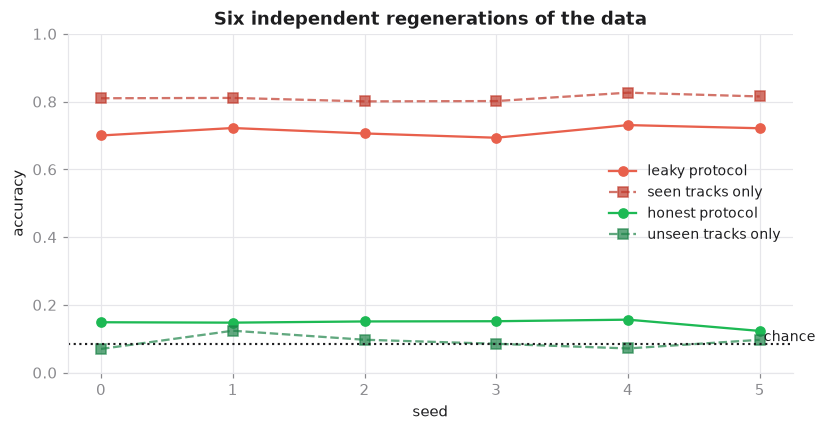

In [15]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(sw))
ax.plot(x, sw["leaky protocol"], "o-", color=viz.WARN, label="leaky protocol")
ax.plot(x, sw["seen tracks"], "s--", color="#c0392b", label="seen tracks only", alpha=.7)
ax.plot(x, sw["honest protocol"], "o-", color=viz.ACCENT, label="honest protocol")
ax.plot(x, sw["unseen tracks"], "s--", color="#1e8449", label="unseen tracks only", alpha=.7)
ax.axhline(S.CHANCE_ACCURACY, color=viz.INK, ls=":", lw=1.4)
ax.text(len(sw) - 1, S.CHANCE_ACCURACY, " chance", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xlabel("seed"); ax.set_ylabel("accuracy")
ax.set_title("Six independent regenerations of the data")
ax.legend(fontsize=9); ax.set_ylim(0, 1)
plt.show()

Three things are stable across every seed, and one is not:

- **The gap is always enormous.** Accuracy on seen tracks sits in a tight band around
  80%; on unseen tracks it hovers near the chance line. The two bands never come close
  to touching.
- **Unseen-track accuracy is chance.** It lands above the chance line in some seeds and
  below it in others, which is precisely what "no signal" looks like. Any single-seed
  value here — high or low — should not be quoted; the spread is the finding.
- **The honest protocol clears chance in every seed**, by a few points, significant each
  time. Small, but consistently there.
- **Which model wins the honest protocol is not stable.** It changes between seeds. With
  every model clustered a few points above chance, the ordering is noise, so do not
  claim a best algorithm for this task.

## 6 · A control, to check the protocol is not simply harsh

A fair objection: perhaps the honest protocol is too severe and would report chance even
on data with genuine signal. If so it is useless.

Test it directly. Regenerate the labelled set three times — once with the signal switched
off entirely (labels are pure noise, nothing to learn by construction), once as normal,
and once with the signal turned way up. A sound protocol reports chance for the first and
clearly beats chance for the third.

In [16]:
if data.using_real_data()["zodiac"]:
    print("Real zodiac data loaded — skipping the synthetic control.")
else:
    rows = []
    for strength, label in [(0.0, "no signal (pure noise)"),
                            (0.45, "weak signal (default)"),
                            (3.0, "strong signal")]:
        zs = syn.make_zodiac_playlists(catalog, signal_strength=strength, seed=11)
        tr_n, te_n = Z.naive_split(zs, 0.25, seed=0)
        cl = Z.deduplicate(zs, "majority")
        tr_h, te_h = Z.honest_split(cl, 0.25, seed=0)
        rows.append({"data": label,
                     "leaky protocol": Z.benchmark(tr_n, te_n)["accuracy"].max(),
                     "honest protocol": Z.benchmark(tr_h, te_h)["accuracy"].max(),
                     "chance": S.CHANCE_ACCURACY})
    control = pd.DataFrame(rows)
    display(control.round(4))

,data,leaky protocol,honest protocol,chance
0,no signal (pure noise),0.702,0.0907,0.0833
1,weak signal (default),0.700,0.1487,0.0833
2,strong signal,0.696,0.6474,0.0833


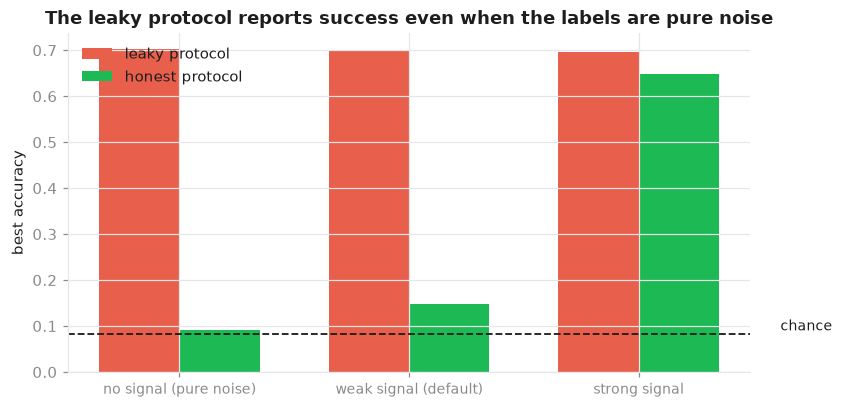

In [17]:
if not data.using_real_data()["zodiac"]:
    x = np.arange(len(control)); w = .35
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.bar(x - w/2, control["leaky protocol"], w, label="leaky protocol", color=viz.WARN)
    ax.bar(x + w/2, control["honest protocol"], w, label="honest protocol", color=viz.ACCENT)
    ax.axhline(S.CHANCE_ACCURACY, color=viz.INK, ls="--", lw=1.2)
    ax.text(len(control) - .4, S.CHANCE_ACCURACY, " chance", va="bottom", fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(control["data"], fontsize=9)
    ax.set_ylabel("best accuracy"); ax.legend()
    ax.set_title("The leaky protocol reports success even when the labels are pure noise")
    plt.show()

Read the leftmost pair first. Those labels are **random by construction** —
there is genuinely nothing to learn. The leaky protocol still reports a number far above
chance. It would have reported a success on data containing no information whatsoever.

The honest protocol correctly returns chance there, and does detect the injected signal
on the right. So it is measuring the right thing rather than simply being pessimistic.

**This control is the single most valuable cell in the notebook**, and it is cheap:
shuffle your labels, re-run your pipeline, and confirm the result collapses. Any pipeline
that still reports success on shuffled labels is measuring itself.

## 7 · A second, independent ceiling

Separate from leakage: when curators file the same track under different signs, those
rows contradict each other and no function of the audio can satisfy both.

Quantify it with an **oracle** handed each track's majority label outright. Note what
that oracle is — a per-track lookup table, precisely what the leaky model approximates.
Its score is therefore not a target to aim for; the shortfall below it measures how much
curators disagree.

In [18]:
counts = zodiac.groupby([S.TRACK_ID, S.STAR_SIGN]).size().rename("n").reset_index()
total = counts.groupby(S.TRACK_ID)["n"].sum()
best_per_track = counts.groupby(S.TRACK_ID)["n"].max()
ceiling = float(best_per_track.sum() / total.sum())

print(f"oracle accuracy on the raw scrape : {ceiling:.1%}")
print(f"honest protocol                   : {res_honest['accuracy'].max():.1%}")
print(f"chance                            : {S.CHANCE_ACCURACY:.1%}")

multi = counts.groupby(S.TRACK_ID)[S.STAR_SIGN].nunique()
contested = multi[multi > 1].index
sub = counts[counts[S.TRACK_ID].isin(contested)]
oracle_contested = float(sub.groupby(S.TRACK_ID)["n"].max().sum() / sub["n"].sum())

print(f"\n--- restricted to tracks curators disagreed about ---")
print(f"share of all rows                  : {zodiac[S.TRACK_ID].isin(contested).mean():.1%}")
print(f"oracle accuracy on just those rows : {oracle_contested:.1%}")
print(f"  even knowing the majority label, {1-oracle_contested:.1%} of those rows are "
      f"wrong by construction")

oracle accuracy on the raw scrape : 88.4%
honest protocol                   : 14.9%
chance                            : 8.3%

--- restricted to tracks curators disagreed about ---
share of all rows                  : 28.3%
oracle accuracy on just those rows : 59.1%
  even knowing the majority label, 40.9% of those rows are wrong by construction


## 8 · Making the feature worth shipping anyway

The classifier is weak. That does not kill the product idea — "a playful summary of your
music taste" never needed a strong classifier. It needed an honest one. Three changes.

### Change 1 — average probabilities, not votes

Hard-classifying each song and counting labels throws away everything the model was
unsure about: a song it scored 51/49 becomes a whole vote. Averaging `predict_proba`
keeps that uncertainty.

In [19]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(clean[S.AUDIO_FEATURES].to_numpy(float), clean[S.STAR_SIGN].to_numpy())

listens, taste = data.load_listens(catalog, n_users=250, tracks_per_user=150)
user_id = listens[S.USER_ID].iloc[0]
user_tracks = listens[listens[S.USER_ID] == user_id]

mix = Z.taste_mix(model, user_tracks)
votes = pd.Series(model.predict(user_tracks[S.AUDIO_FEATURES].to_numpy(float))).value_counts(normalize=True)

cmp = pd.DataFrame({"averaged probability": mix, "hard votes": votes}).fillna(0).round(4)
cmp.sort_values("averaged probability", ascending=False)

[data] SYNTHETIC users. Drop real histories at /Users/akintunjisule/Desktop/AIM-Music-Matching/ml/data/raw/listens.csv to use yours.


,averaged probability,hard votes
Aries,0.0875,0.1133
Aquarius,0.0874,0.1400
Taurus,0.0872,0.1133
Cancer,0.0870,0.1000
Pisces,0.0851,0.0267
Libra,0.0843,0.1600
Capricorn,0.0839,0.0733
Gemini,0.0834,0.1067
Scorpio,0.0820,0.0467
Leo,0.0804,0.0333


Whole signs collapse to zero in the hard-vote column, because no individual
song happened to win them outright. The probability column keeps the shape of the user's
taste intact.

### Change 2 — report lift over the base rate

This is the important one. A pie chart reading *11.9% Capricorn, 4.3% Scorpio* invites
the user to read meaning into those numbers. But what does the model say about
**everyone**?

In [20]:
base = Z.base_rate(model, catalog)
side = pd.DataFrame({"this user": mix, "average listener": base})
side["lift"] = side["this user"] / side["average listener"]
side.sort_values("lift", ascending=False).round(3)

,this user,average listener,lift
Pisces,0.085,0.076,1.114
Taurus,0.087,0.079,1.106
Cancer,0.087,0.081,1.074
Aries,0.088,0.084,1.042
Gemini,0.083,0.082,1.015
Libra,0.084,0.085,0.991
Scorpio,0.082,0.084,0.971
Virgo,0.080,0.083,0.966
Aquarius,0.087,0.091,0.964
Capricorn,0.084,0.087,0.962


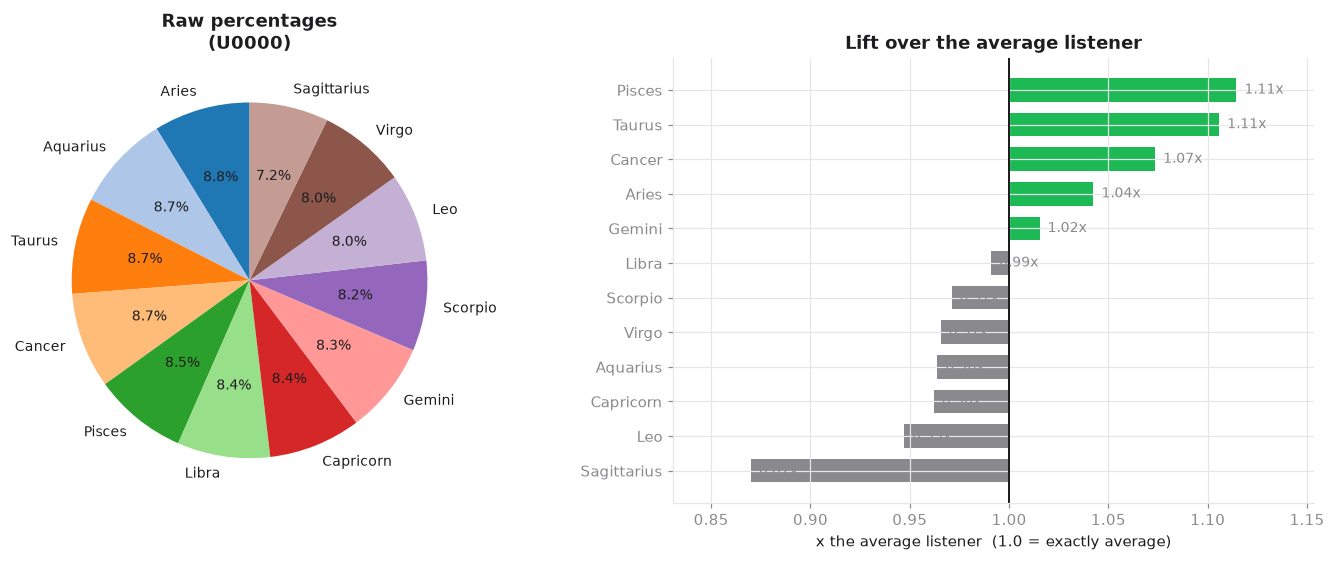

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
viz.taste_mix_pie(mix, f"Raw percentages\n({user_id})", ax=axes[0])
viz.lift_chart(Z.lift(mix, base), "Lift over the average listener", ax=axes[1])
plt.tight_layout(); plt.show()

The pie on the left is largely a picture of the **class prior** — close to the
shape the model produces for anybody at all. The chart on the right subtracts that away,
leaving only the part that is about this particular user.

"You are 1.4× more Libra than the average listener" is a claim about a person. "You are
9.5% Pisces" is mostly a claim about the model.

### Change 3 — say when there is nothing to say

With a weak classifier most users will sit near 1.0× on every sign. The feature should
admit that rather than manufacture a personality for them.

users whose strongest sign exceeds 1.25x the base rate: 27.2%
median top lift across all users: 1.18x


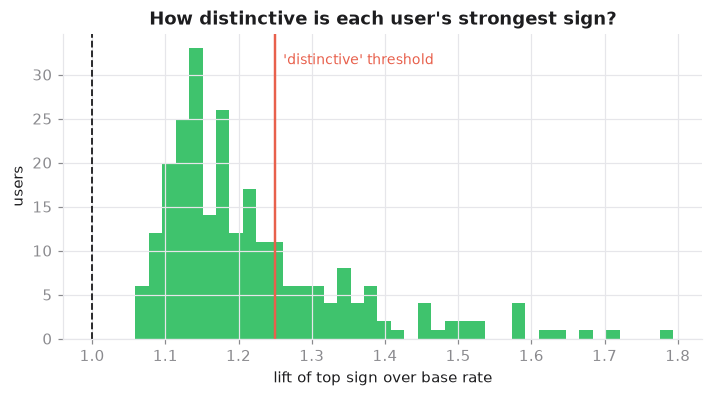

In [22]:
rows = []
for u, g in listens.groupby(S.USER_ID):
    l = Z.lift(Z.taste_mix(model, g), base)
    rows.append({"user": u, "top_sign": l.index[0], "top_lift": l.iloc[0]})
dist = pd.DataFrame(rows)

print(f"users whose strongest sign exceeds 1.25x the base rate: {(dist['top_lift'] >= 1.25).mean():.1%}")
print(f"median top lift across all users: {dist['top_lift'].median():.2f}x")

fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.hist(dist["top_lift"], bins=40, color=viz.ACCENT, alpha=.85)
ax.axvline(1.0, color=viz.INK, ls="--", lw=1.2)
ax.axvline(1.25, color=viz.WARN, lw=1.6)
ax.text(1.25, ax.get_ylim()[1]*.9, "  'distinctive' threshold", color=viz.WARN, fontsize=9)
ax.set_title("How distinctive is each user's strongest sign?")
ax.set_xlabel("lift of top sign over base rate"); ax.set_ylabel("users")
plt.show()

`service.LovifyModels.taste_profile()` implements exactly this and returns
`is_distinctive: False` when the top lift falls below 1.25×, so the UI can present the
mix as a bit of fun rather than as a reading.

## What this means for the scrape

Everything above ran on generated data. The specific percentages will differ on real
playlists. The **mechanism** will not: it follows from playlists overlapping, which is a
fact about how people make playlists, and the scrape audit already measures that overlap
directly.

So these are requirements for the collection pipeline, not suggestions:

| requirement | why | status |
|---|---|---|
| Deduplicate to one row per track before splitting | leakage is otherwise unavoidable | `zodiac.deduplicate()` |
| Group splits by track, never split rows | same track must not straddle the split | `zodiac.honest_split()`, `GroupKFold` |
| Group by **playlist cluster** too | copied playlists leak even after track dedup | `dedup.cluster_playlists()` |
| Report every accuracy against the 8.3% chance rate | an unanchored accuracy is uninterpretable | every chart here |
| Run the shuffled-label control on the real data | catches any leak we have not thought of | §6 |
| Report mean ± std over seeds, never one run | single-seed values here varied widely | §5 |

### What to expect from the real data

On the honest protocol: a few points above chance, if anything. The ceiling is set by
curator disagreement rather than by algorithm choice, so better models will not move it —
only better labels will.

Treat that as a result rather than a disappointment. "We measured it properly and the
effect is small" is a finding, and it is one most projects never reach because they stop
at the first impressive number. The alternative was shipping a 75% that would have
collapsed the moment it met a song outside the training set.

→ `02_user_similarity.ipynb`